# Forecast Verification (Backtesting)
Since we do not have actual data for 168 hours to verify against, we must use **backtesting**. Run 2 only contains data from **16.46 hours to 16.72 hours**. We artificially hide the data from **16.6 hours** onwards, train our model on `16.46h to 16.6h`, and ask it to predict the condition in the hidden test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, mean_absolute_error

df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_01.csv')
df_run2 = df[df['Run_ID'] == 2].dropna(subset=['Aging_Hours', 'RDS_on_Ohm']).sort_values('Aging_Hours')

cutoff_hour = 16.6
train_df = df_run2[df_run2['Aging_Hours'] <= cutoff_hour]
test_df = df_run2[df_run2['Aging_Hours'] > cutoff_hour]

print(f"Training on {len(train_df)} points (up to 16.6h).")
print(f"Testing on {len(test_df)} points (after 16.6h).")

X_train = train_df[['Aging_Hours']]
y_train = train_df['RDS_on_Ohm']

X_test = test_df[['Aging_Hours']]
y_test = test_df['RDS_on_Ohm']

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

print(f"--- REGRESSION ERROR ---")
print(f"Mean Absolute Error (MAE) for future points: {mae:.4f} Ohm")

# Classification Verification (Anomaly Detection)
threshold = 0.85
actual_flags = (y_test > threshold).astype(int)
predicted_flags = (y_pred > threshold).astype(int)

acc = accuracy_score(actual_flags, predicted_flags)
rec = recall_score(actual_flags, predicted_flags, zero_division=0)
prec = precision_score(actual_flags, predicted_flags, zero_division=0)

print("\n--- CLASSIFICATION METRICS (Forecast Verification) ---")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")


Training on 503 points (up to 16.6h).
Testing on 973 points (after 16.6h).
--- REGRESSION ERROR ---
Mean Absolute Error (MAE) for future points: 1.1070 Ohm

--- CLASSIFICATION METRICS (Forecast Verification) ---
Accuracy : 97.74%
Recall   : 100.00%
Precision: 97.74%


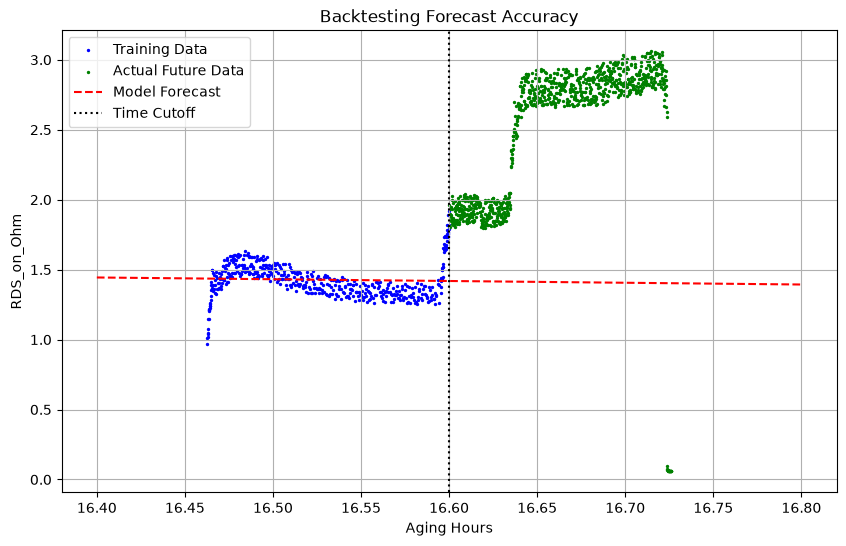

In [2]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', s=2, label='Training Data')
plt.scatter(X_test, y_test, color='green', s=2, label='Actual Future Data')

X_plot = pd.DataFrame({'Aging_Hours': np.linspace(16.4, 16.8, 500)})
plt.plot(X_plot, model.predict(X_plot), color='red', linestyle='--', label='Model Forecast')

plt.axvline(x=cutoff_hour, color='black', linestyle=':', label='Time Cutoff')
plt.title('Backtesting Forecast Accuracy')
plt.xlabel('Aging Hours')
plt.ylabel('RDS_on_Ohm')
plt.legend()
plt.grid(True)
plt.show()
